# Library of Logic Gate Contracts Using Cello
### Ayush Pandey

Cello is a biocircuit design tool that uses a characterized genetic logic gates library to compose parts that meet a specification in Verilog. We use these characterizations to construct a library of polyhedral assume guarantee contract specifications for compositional design with the same characterized biological parts.

For the NOR gates in Cello, the response function is
$$y=y_{\min}+\frac{y_{\max}-y_{\min}}{1+q},\qquad q=(u/K)^n,$$
where $u$ is the aggregate input promoter activity and $y$ is the output promoter activity, both in RPU. For the AND gates, the two input promoter activities $u_1,u_2$ give
$$y=y_{\min}+(y_{\max}-y_{\min})\frac{q_1}{1+q_1}\frac{q_2}{1+q_2},\qquad q_i=(u_i/K_i)^n.$$
The library parameters satisfy $0<y_{\min}<y_{\max}$, with positive thresholds $K,K_i$ and exponent $n$.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from biospeak.cello import (
    build_library,
    construct,
    load_gates,
    response,
)

plt.rcParams.update({"font.size": 16, "pdf.fonttype": 42})
gates = load_gates()
pd.DataFrame(gates).set_index("name")

,type,ymax,ymin,K,n,IL,IH,equation,K1,K2,IL1,IH1,IL2,IH2
name,,,,,,,,,,,,,,
A1_AmtR,NOR,3.8,0.060,0.07,1.6,0.071418,0.917082,ymin+(ymax-ymin)/(1.0+(x/K)^n),NaN,NaN,NaN,NaN,NaN,NaN
B1_BM3R1,NOR,0.5,0.004,0.04,3.4,0.040190,0.164717,ymin+(ymax-ymin)/(1.0+(x/K)^n),NaN,NaN,NaN,NaN,NaN,NaN
B2_BM3R1,NOR,0.5,0.005,0.15,2.9,0.151049,0.728989,ymin+(ymax-ymin)/(1.0+(x/K)^n),NaN,NaN,NaN,NaN,NaN,NaN
B3_BM3R1,NOR,0.8,0.010,0.26,3.4,0.261943,0.936422,ymin+(ymax-ymin)/(1.0+(x/K)^n),NaN,NaN,NaN,NaN,NaN,NaN
E1_BetI,NOR,3.8,0.070,0.41,2.4,0.416463,2.131949,ymin+(ymax-ymin)/(1.0+(x/K)^n),NaN,NaN,NaN,NaN,NaN,NaN
F1_AmeR,NOR,3.8,0.200,0.09,1.4,0.097442,0.680980,ymin+(ymax-ymin)/(1.0+(x/K)^n),NaN,NaN,NaN,NaN,NaN,NaN
H1_HlyIIR,NOR,2.5,0.070,0.19,2.6,0.194258,0.735147,ymin+(ymax-ymin)/(1.0+(x/K)^n),NaN,NaN,NaN,NaN,NaN,NaN
I1_IcaRA,NOR,2.2,0.080,0.10,1.4,0.105541,1.010815,ymin+(ymax-ymin)/(1.0+(x/K)^n),NaN,NaN,NaN,NaN,NaN,NaN
L1_LitR,NOR,4.3,0.070,0.05,1.7,0.050983,0.552709,ymin+(ymax-ymin)/(1.0+(x/K)^n),NaN,NaN,NaN,NaN,NaN,NaN


## Construct the contract library

Both response functions have the positive monomial sum quotient form. We write each as $y=A(u)/B(u)$ and apply the construction to the balance $yB(u)=A(u)$, then refine its guarantees.

We divide each input into low, transition, and high intervals and construct a contract for each of the three joint regions. We obtain three contracts for each characterized gate, giving a library of 66 contracts for 22 response curves.

In [2]:
library = build_library(gates)
assert len(library) == 22
assert sum(len(entries) for entries in library.values()) == 66
print(library["P1_PhlF"]["transition"])

InVars: [zu]
OutVars:[zy]
A: [
  -zu <= 3.505
  zu <= -2.016
]
G: [
  -4 zu - zy <= 13.35
  4 zu + zy <= -11.98
  -zy <= 4.605
  zy <= 1.361
  -3.528 zu - zy <= 11.7
  -1.543 zu - zy <= 7.023
  1.543 zu + zy <= -4.741
  3.528 zu + zy <= -11.02
]


## P1_PhlF

We illustrate one NOR contract using P1_PhlF, with the monomial ratio guarantees and the tighter refined guarantees shown.

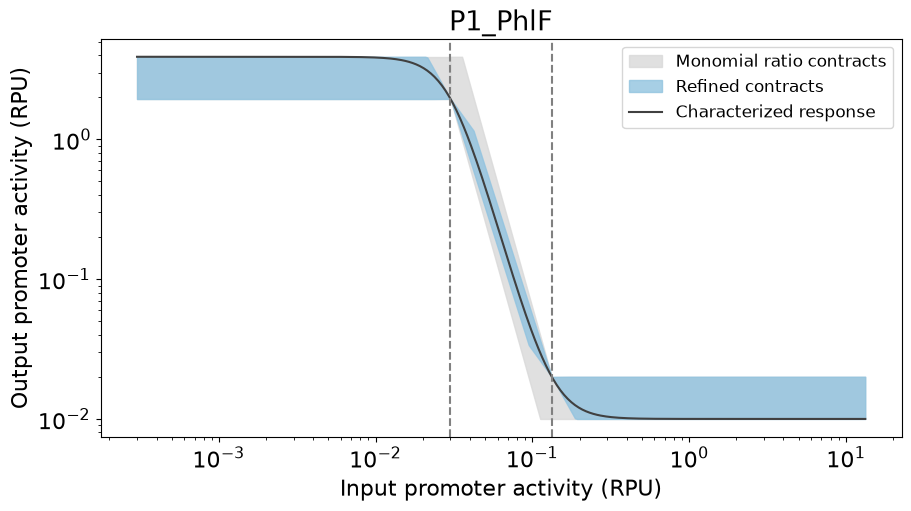

In [3]:
gate = next(g for g in gates if g["name"] == "P1_PhlF")
fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
for index, (mode, domain) in enumerate(
    zip(
        ["low", "transition", "high"],
        [
            (gate["IL"] / 100, gate["IL"]),
            (gate["IL"], gate["IH"]),
            (gate["IH"], gate["IH"] * 100),
        ],
    )
):
    u = np.geomspace(*domain, 150)
    contract, data, details = construct(gate, (mode,))
    for rows, color, label in [
        (
            details["monomial_ratio_contract"]["guarantees"],
            "0.85",
            "Monomial ratio contracts",
        ),
        (data["guarantees"], "#91c3df", "Refined contracts"),
    ]:
        lower, upper = [], []
        for term in rows:
            coefficients = term["coefficients"]
            a = coefficients.get("zy", 0)
            if not a:
                continue
            bound = (term["constant"] - coefficients.get("zu", 0) * np.log(u)) / a
            (lower if a < 0 else upper).append(bound)
        lo, hi = np.exp(np.maximum.reduce(lower)), np.exp(np.minimum.reduce(upper))
        ax.fill_between(
            u, lo, hi, color=color, alpha=0.8, label=label if index == 0 else None
        )
    y = response(gate, [u])
    assert np.all(y >= lo - 1e-9) and np.all(y <= hi + 1e-9)
u = np.geomspace(gate["IL"] / 100, gate["IH"] * 100, 400)
ax.plot(u, response(gate, [u]), color="0.25", label="Characterized response")
ax.axvline(gate["IL"], color="0.5", ls="--")
ax.axvline(gate["IH"], color="0.5", ls="--")
ax.set(
    xscale="log",
    yscale="log",
    xlabel="Input promoter activity (RPU)",
    ylabel="Output promoter activity (RPU)",
    title="P1_PhlF",
)
ax.legend(fontsize=12)
plt.show()

## AND gates

For an AND response, each assumption places conditions on both input promoter activities.

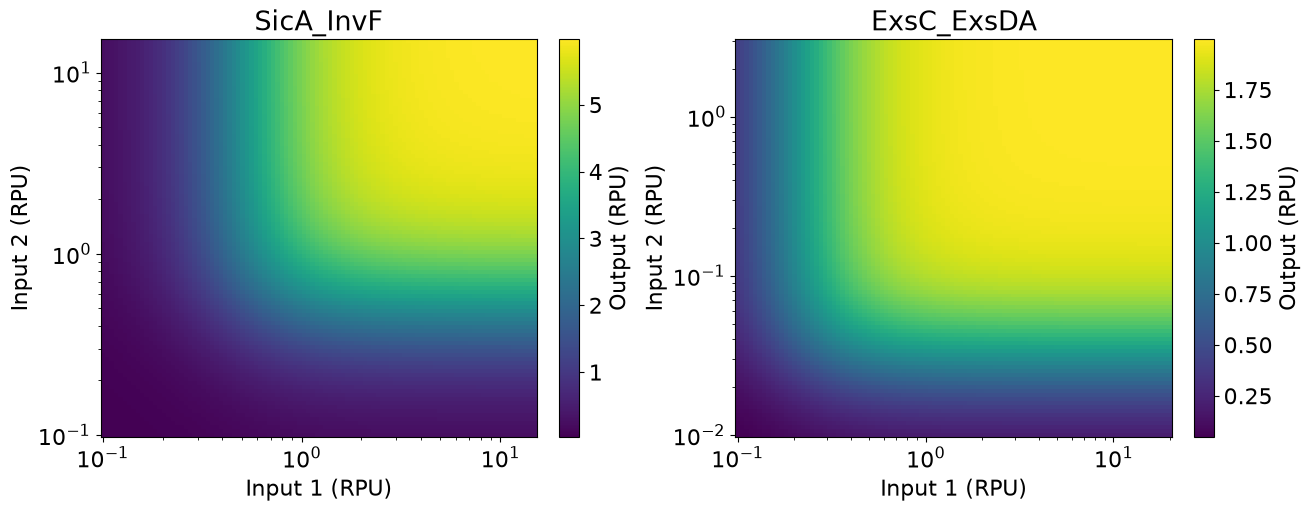

In [4]:
and_gates = [gate for gate in gates if gate["type"] == "AND"]
fig, axes = plt.subplots(1, len(and_gates), figsize=(13, 5), layout="constrained")
for ax, gate in zip(axes, and_gates):
    u1 = np.geomspace(gate["IL1"] / 10, gate["IH1"] * 10, 100)
    u2 = np.geomspace(gate["IL2"] / 10, gate["IH2"] * 10, 100)
    U1, U2 = np.meshgrid(u1, u2)
    image = ax.pcolormesh(
        U1, U2, response(gate, [U1, U2]), shading="auto", cmap="viridis"
    )
    ax.set(
        xscale="log",
        yscale="log",
        xlabel="Input 1 (RPU)",
        ylabel="Input 2 (RPU)",
        title=gate["name"],
    )
    fig.colorbar(image, ax=ax, label="Output (RPU)")
plt.show()

Gate characterizations: [Cello UCF](https://github.com/CIDARLAB/Cello-UCF) and [Cello gate libraries](https://github.com/CIDARLAB/cello).